
# =============================================================
# ЛАБОРАТОРНАЯ РАБОТА №1: Оценка экономической эффективности внедрения облачной CRM
# =============================================================
# Дата: 2026-09-20
# Студент: Мироненкова Валерия Руслановна
# Группа: ПИ 4-2
# =============================================================
## Принятые экономические аксиомы

1. CRM высвобождает часть рабочего времени менеджеров: 30% рутинных операций × 20% экономии = 6% рабочего времени.
2. Численность менеджеров в базовом сценарии не сокращается, поэтому 1,296 млн руб. — это стоимость высвобождаемого рабочего времени, а не непосредственная экономия денежных выплат по зарплате.
3. Высвобожденное время используется для работы с клиентами и связано с дополнительным ростом продаж на 8%. Поэтому стоимость времени не прибавляется второй раз к эффекту от роста продаж.
4. Для дополнительного объёма продаж предельные затраты принимаются незначительными относительно дополнительной выручки. Поэтому в базовом сценарии прирост выручки трактуется как прирост маржинальной прибыли (`marginal_profit_rate = 1.0`).
5. Эффект CRM не реализуется в первый месяц из-за обучения и адаптации; поэтому в первом году учитывается 11/12 годового эффекта.
6. Лицензии оплачиваются в начале каждого года; стоимость внедрения, если она не дана в условии, в базовом расчёте не выдумывается и принимается равной нулю. Её можно задать отдельной переменной.
7. ROI определяется как отношение совокупного чистого эффекта за горизонт проекта к совокупным денежным затратам проекта.


## 1. Исходные данные 

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# ИСХОДНЫЕ ДАННЫЕ
# ============================================================

managers = 15
monthly_salary = 120_000
routine_share = 0.30
crm_time_saving = 0.20

annual_sales = 72_000_000
crm_sales_growth = 0.08

crm_price_per_user_year = 24_000
implementation_cost = 0

adaptation_months = 1

tax_rate = 0.20
discount_rate = 0.12
project_years = 3

# ============================================================
# ЭКОНОМИЧЕСКИЕ АКСИОМЫ 
# ============================================================

# Доля дополнительной выручки, превращающаяся в маржинальную прибыль.
# База = 1.0: предельные затраты считаются незначительными.
marginal_profit_rate = 1.00

# Доля стоимости высвобождаемого времени, которая реально
# превращается именно в экономию ФОТ.
# База = 0: персонал не сокращается, время направляется на продажи.
realized_salary_saving_rate = 0.00

print("Параметры загружены.")


Параметры загружены.


## Экономические аксиомы 

### Аксиома 1. Высвобождение рабочего времени не является прямой экономией ФОТ

CRM позволяет сократить время, затрачиваемое менеджерами на рутинные операции.

Доля высвобождаемого рабочего времени определяется как:

$$
d_{free}=d_{routine}\times e_{CRM}
$$

где:

- $d_{routine}=30\%$ — доля рабочего времени, затрачиваемого на рутинные операции;
- $e_{CRM}=20\%$ — снижение времени на выполнение этих операций.

Следовательно:

$$
d_{free}=30\%\times20\%=6\%.
$$

Однако высвобождение 6% рабочего времени не означает автоматического сокращения расходов на заработную плату. В условии не указано, что после внедрения CRM количество менеджеров будет сокращено.

Поэтому принимается:

\[
realized\_salary\_saving\_rate=0.
\]

То есть в базовом сценарии **экономия ФОТ в денежном выражении отсутствует**.

Высвободившееся время рассматривается как ресурс, который может быть использован менеджерами для работы с клиентами и увеличения продаж.

---

### Аксиома 2. Высвобожденное рабочее время используется для увеличения продаж

Предполагается, что компания не сокращает штат после внедрения CRM, а перераспределяет высвободившееся время менеджеров на более продуктивные операции: работу с клиентами, обработку заявок, сопровождение сделок и развитие продаж.

Таким образом, экономический эффект от высвобождения времени реализуется через рост продаж.

Стоимость высвобожденного рабочего времени при этом рассчитывается отдельно как аналитический показатель:

$$
V_{time}=ФОТ_{год}\times d_{free}.
$$

Но эта величина **не прибавляется повторно к приросту прибыли от продаж**, поскольку оба эффекта связаны с одним и тем же высвобождением рабочего времени.

Такое решение позволяет избежать двойного учета экономического эффекта.

---

### Аксиома 3. Предельные затраты на дополнительную выручку считаются незначительными

В условии дана величина текущего оборота и прогноз роста продаж после внедрения CRM, однако не указана себестоимость дополнительного объема продаж или переменные затраты.

Поэтому необходимо ввести предположение о предельных затратах.

В базовом сценарии принимается, что дополнительный объем продаж может быть реализован существующими сотрудниками и с использованием существующей инфраструктуры компании.

Следовательно, предельные затраты на дополнительную реализацию считаются незначительными относительно дополнительной выручки:

$$
MC\approx0.
$$

Поэтому:

$$
\Delta MP\approx\Delta R,
$$

где:

- $\Delta MP$ — прирост маржинальной прибыли;
- $\Delta R$ — прирост выручки.

Именно поэтому в модели:

$$
marginal\_profit\_rate=1.00.
$$

Это не означает, что у компании вообще отсутствуют затраты на продажи. Предполагается только, что **дополнительные (предельные) затраты на рассматриваемый прирост продаж относительно малы**.

---

### Аксиома 4. Прогноз роста продаж на 8% принимается как экономический эффект CRM

В условии непосредственно задан прогноз роста продаж на 8% в год.

Поэтому дополнительная выручка определяется:

$$
\Delta R=R_0\times g,
$$

где:

- $R_0$ — текущий оборот отдела;
- $g$ — прогнозируемый темп роста продаж.

При заданных значениях:

$$
\Delta R=72\,000\,000\times8\%=5\,760\,000\text{ руб.}
$$

Таким образом, базовый сценарий предполагает получение 5,76 млн руб. дополнительной выручки ежегодно.

---

### Аксиома 5. В первый год эффект от CRM реализуется не полностью

В условии указан период обучения и адаптации продолжительностью 1 месяц.

Предполагается, что в течение этого месяца дополнительный экономический эффект от CRM не реализуется в полном объеме.

Поэтому в первом году учитывается только:

$$
\frac{12-1}{12}=\frac{11}{12}
$$

годового эффекта.

Таким образом:

$$
E_1=E_{year}\times\frac{11}{12}.
$$

Со второго года предполагается полная реализация прогнозируемого эффекта.

---

### Аксиома 6. Налог учитывается на уровне дополнительной прибыли

Поскольку рост продаж приводит к формированию дополнительной маржинальной прибыли, из нее необходимо вычесть налог на прибыль.

При ставке налога 20%:

$$
E_{aftertax}=
\Delta MP\times(1-T).
$$

Таким образом, при отсутствии иных налоговых особенностей дополнительный денежный эффект после налогообложения определяется через ставку налога на прибыль из условия.

---

### Аксиома 7. Стоимость CRM является денежным оттоком проекта

Стоимость CRM составляет 24 000 руб. на одного пользователя в год.

Поскольку пользователями системы являются 15 менеджеров:

$$
C_{CRM}=15\times24\,000=360\,000\text{ руб./год}.
$$

На трехлетнем горизонте:

$$
C_{CRM,3}=360\,000\times3=1\,080\,000\text{ руб.}
$$

В модели предполагается ежегодная оплата лицензий.

---

### Аксиома 8. Стоимость внедрения, не указанная в условии, не должна выдумываться

В условии отсутствует отдельная стоимость внедрения CRM.

Поэтому в базовом сценарии она принимается равной нулю:

$$
C_{implementation}=0.
$$

При этом данный параметр остается переменным в модели.

---

### Аксиома 9. Горизонт оценки составляет три года

Все денежные потоки проекта оцениваются на протяжении трех лет согласно условию.

Для сопоставления денежных потоков разных периодов используется ставка дисконтирования:

$$
r=12\%.
$$

Поэтому для оценки инвестиционной эффективности используется показатель NPV.

---

### Итоговая логика модели

Таким образом, экономический эффект CRM формируется следующим образом:

$$
CRM
\rightarrow
\text{сокращение рутинного времени}
\rightarrow
\text{высвобождение рабочего времени}
\rightarrow
\text{больше времени на продажи}
\rightarrow
\text{рост продаж}
\rightarrow
\text{дополнительная маржинальная прибыль}.
$$

При этом стоимость высвобожденного рабочего времени не прибавляется отдельно к приросту прибыли, чтобы не учитывать один и тот же эффект дважды.

Основным неопределенным параметром модели является фактический рост продаж после внедрения CRM. Поэтому в дальнейшем проводится анализ чувствительности NPV к изменению темпа роста продаж.

In [ ]:
assumptions = pd.DataFrame({
    "Параметр": [
        "Предельные затраты на дополнительную выручку",
        "Доля дополнительной выручки, являющаяся маржинальной прибылью",
        "Доля высвобожденного времени, превращающаяся в экономию ФОТ",
        "Период адаптации"
    ],
    "Значение": [
        "Незначительные",
        f"{marginal_profit_rate:.0%}",
        f"{realized_salary_saving_rate:.0%}",
        f"{adaptation_months} месяц"
    ]
})

assumptions

,Параметр,Значение
0,Предельные затраты на дополнительную выручку,Незначительные
1,"Доля дополнительной выручки, являющаяся маржин...",100%
2,"Доля высвобожденного времени, превращающаяся в...",0%
3,Период адаптации,1 месяц


## 2. Расчеты

In [ ]:
# ФОТ
monthly_payroll = managers * monthly_salary
annual_payroll = monthly_payroll * 12

print(f"Месячный ФОТ: {monthly_payroll:,.0f} руб.")
print(f"Годовой ФОТ: {annual_payroll:,.0f} руб.")


Месячный ФОТ: 1,800,000 руб.
Годовой ФОТ: 21,600,000 руб.


In [ ]:
# Высвобождение времени
freed_time_share = routine_share * crm_time_saving
freed_fte = managers * freed_time_share

# Стоимость высвобождаемого рабочего времени
potential_time_value = annual_payroll * freed_time_share

# Реальная денежная экономия ФОТ
salary_cash_saving = potential_time_value * realized_salary_saving_rate

print(
    f"Стоимость высвобождаемого времени: "
    f"{potential_time_value:,.0f} руб./год"
)


Стоимость высвобождаемого времени: 1,296,000 руб./год


Полученная величина не рассматривается как непосредственная экономия денежных расходов, поскольку численность сотрудников в модели не сокращается. Она отражает стоимость высвобождаемого ресурса труда.

In [ ]:
# Дополнительные продажи
additional_sales = annual_sales * crm_sales_growth

# Дополнительная маржинальная прибыль
additional_margin_profit = additional_sales * marginal_profit_rate

print(
    f"Дополнительная маржинальная прибыль: "
    f"{additional_margin_profit:,.0f} руб./год"
)

Дополнительная маржинальная прибыль: 5,760,000 руб./год


In [ ]:
# Эффект после налога
additional_profit_after_tax = additional_margin_profit * (1 - tax_rate)

# Денежный эффект до затрат на CRM
direct_effect = additional_profit_after_tax + salary_cash_saving

print(
    f"Дополнительная прибыль после налога: "
    f"{additional_profit_after_tax:,.0f} руб./год"
)

Дополнительная прибыль после налога: 4,608,000 руб./год


In [ ]:
# Стоимость CRM

annual_crm_license = (
    managers * crm_price_per_user_year
)

total_crm_license = (
    annual_crm_license * project_years
)

print(f"Стоимость CRM за год: {annual_crm_license:,.0f} руб.")
print(
    f"Стоимость CRM за {project_years} года: "
    f"{total_crm_license:,.0f} руб."
)

Стоимость CRM за год: 360,000 руб.
Стоимость CRM за 3 года: 1,080,000 руб.


In [ ]:
cost_table = pd.DataFrame({
    "Показатель": [
        "Лицензия CRM за 1 год",
        "Лицензии за весь проект",
        "Разовые затраты на внедрение"
    ],
    "Значение, руб.": [
        annual_crm_license,
        total_crm_license,
        implementation_cost
    ]
})

cost_table

,Показатель,"Значение, руб."
0,Лицензия CRM за 1 год,360000
1,Лицензии за весь проект,1080000
2,Разовые затраты на внедрение,0


In [ ]:
direct_effect_table = pd.DataFrame({
    "Показатель": [
        "Годовой ФОТ менеджеров",
        "Высвобождаемая доля рабочего времени",
        "Эквивалент высвобожденных FTE",
        "Стоимость высвобождаемого времени",
        "Дополнительная выручка от CRM",
        "Дополнительная маржинальная прибыль",
        "Дополнительная прибыль после налога"
    ],
    "Значение": [
        annual_payroll,
        freed_time_share,
        freed_fte,
        potential_time_value,
        additional_sales,
        additional_margin_profit,
        additional_profit_after_tax
    ]
})

direct_effect_table

,Показатель,Значение
0,Годовой ФОТ менеджеров,21600000.00
1,Высвобождаемая доля рабочего времени,0.06
2,Эквивалент высвобожденных FTE,0.90
3,Стоимость высвобождаемого времени,1296000.00
4,Дополнительная выручка от CRM,5760000.00
5,Дополнительная маржинальная прибыль,5760000.00
6,Дополнительная прибыль после налога,4608000.00


### Интерпретация

CRM высвобождает 6% рабочего времени, что эквивалентно 0,9 ставки менеджера. Денежная стоимость этого времени составляет 1,296 млн руб. в год.

Однако в базовой модели это не считается отдельной экономией ФОТ, поскольку численность работников не сокращается. Высвобожденное время используется для роста продаж, поэтому его нельзя одновременно добавить к приросту продаж без риска двойного счёта.


### Денежные потоки, NPV, ROI и срок окупаемости

Лицензия оплачивается в начале каждого года. В момент 0 учитывается первый платёж за лицензию и разовые затраты на внедрение. В первый год эффект CRM реализуется только 11 месяцев из 12.


In [ ]:
# Денежные потоки, NPV, ROI и срок окупаемости
def calculate_project():
    years = np.arange(0, project_years + 1)

    cash_flows = []
    benefits = []
    costs = []
    discount_factors = []
    discounted_cf = []

    for year in years:
        if year == 0:
            benefit = 0
            cost = annual_crm_license + implementation_cost

        elif year == 1:
            realization_factor = max(0, (12 - adaptation_months) / 12)
            benefit = direct_effect * realization_factor
            cost = annual_crm_license

        else:
            benefit = direct_effect
            cost = annual_crm_license

        cf = benefit - cost
        df = 1 / ((1 + discount_rate) ** year)

        benefits.append(benefit)
        costs.append(cost)
        cash_flows.append(cf)
        discount_factors.append(df)
        discounted_cf.append(cf * df)

    df = pd.DataFrame({
        "Год": years,
        "Эффект, руб.": benefits,
        "Затраты, руб.": costs,
        "Чистый денежный поток, руб.": cash_flows,
        "Коэффициент дисконтирования": discount_factors,
        "Дисконтированный денежный поток, руб.": discounted_cf
    })

    df["Накопленный денежный поток, руб."] = df["Чистый денежный поток, руб."].cumsum()
    df["Накопленный дисконтированный поток, руб."] = df["Дисконтированный денежный поток, руб."].cumsum()

    npv = df["Дисконтированный денежный поток, руб."].sum()
    total_benefits = df["Эффект, руб."].sum()
    total_costs = df["Затраты, руб."].sum()
    total_net_effect = total_benefits - total_costs

    # ROI = совокупный чистый эффект / совокупные затраты
    roi = total_net_effect / total_costs if total_costs else np.nan

    # Простой срок окупаемости.
    # Первый месяц — адаптация, затем возникает равномерный месячный эффект.
    monthly_benefit = direct_effect / 12
    initial_investment = annual_crm_license + implementation_cost

    if monthly_benefit > 0:
        simple_payback_months = adaptation_months + initial_investment / monthly_benefit
    else:
        simple_payback_months = np.inf

    # Дисконтированный срок окупаемости считаем помесячно,
    # чтобы корректно учесть 1 месяц адаптации.
    monthly_discount_rate = (1 + discount_rate) ** (1 / 12) - 1
    monthly_cash_flows = []

    for month in range(project_years * 12 + 1):
        benefit_m = 0

        # Эффект начинается после периода адаптации
        if month > adaptation_months:
            benefit_m = direct_effect / 12

        # Лицензия оплачивается в начале проекта и затем в начале
        # второго и третьего годов.
        cost_m = 0
        if month == 0:
            cost_m += annual_crm_license + implementation_cost
        elif month in [12 * y for y in range(1, project_years)]:
            cost_m += annual_crm_license

        monthly_cash_flows.append(benefit_m - cost_m)

    discounted_payback_months = np.inf
    cumulative_monthly = 0

    for month, cf_m in enumerate(monthly_cash_flows):
        discounted_m = cf_m / ((1 + monthly_discount_rate) ** month)
        previous = cumulative_monthly
        cumulative_monthly += discounted_m

        if previous < 0 and cumulative_monthly >= 0:
            discounted_payback_months = (
                (month - 1)
                + (-previous) / (cumulative_monthly - previous)
            )
            break

    metrics = {
        "NPV, руб.": npv,
        "Совокупный эффект, руб.": total_benefits,
        "Совокупные затраты, руб.": total_costs,
        "Совокупный чистый эффект, руб.": total_net_effect,
        "ROI, %": roi * 100,
        "Простой срок окупаемости, мес.": simple_payback_months,
        "Дисконтированный срок окупаемости, мес.": discounted_payback_months
    }

    return df, metrics


cashflow_table, metrics = calculate_project()
cashflow_table


,Год,"Эффект, руб.","Затраты, руб.","Чистый денежный поток, руб.",Коэффициент дисконтирования,"Дисконтированный денежный поток, руб.","Накопленный денежный поток, руб.","Накопленный дисконтированный поток, руб."
0,0,0.0,360000,-360000.0,1.000000,-3.600000e+05,-360000.0,-3.600000e+05
1,1,4224000.0,360000,3864000.0,0.892857,3.450000e+06,3504000.0,3.090000e+06
2,2,4608000.0,360000,4248000.0,0.797194,3.386480e+06,7752000.0,6.476480e+06
3,3,4608000.0,360000,4248000.0,0.711780,3.023642e+06,12000000.0,9.500122e+06


In [ ]:
metrics_table = pd.DataFrame({
    "Показатель": list(metrics.keys()),
    "Результат": list(metrics.values())
})

metrics_table


,Показатель,Результат
0,"NPV, руб.",9.500122e+06
1,"Совокупный эффект, руб.",1.344000e+07
2,"Совокупные затраты, руб.",1.440000e+06
3,"Совокупный чистый эффект, руб.",1.200000e+07
4,"ROI, %",8.333333e+02
5,"Простой срок окупаемости, мес.",1.937500e+00
6,"Дисконтированный срок окупаемости, мес.",1.955376e+00


Визуализация

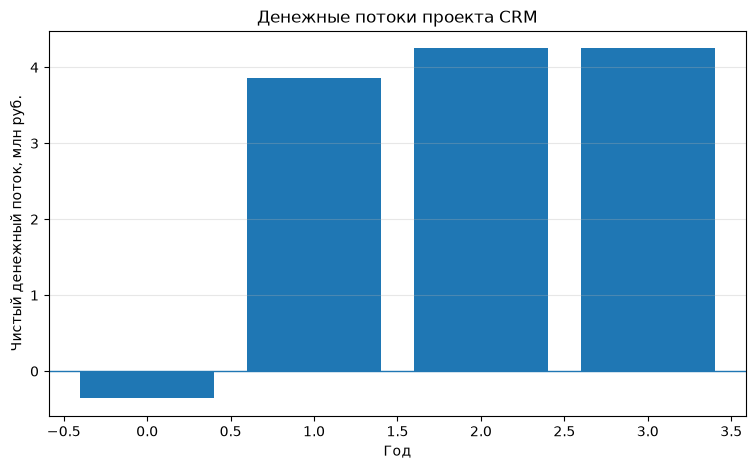

In [ ]:
plt.figure(figsize=(9, 5))
plt.bar(
    cashflow_table["Год"],
    cashflow_table["Чистый денежный поток, руб."] / 1e6
)
plt.axhline(0, linewidth=1)
plt.xlabel("Год")
plt.ylabel("Чистый денежный поток, млн руб.")
plt.title("Денежные потоки проекта CRM")
plt.grid(axis="y", alpha=0.3)
plt.show()


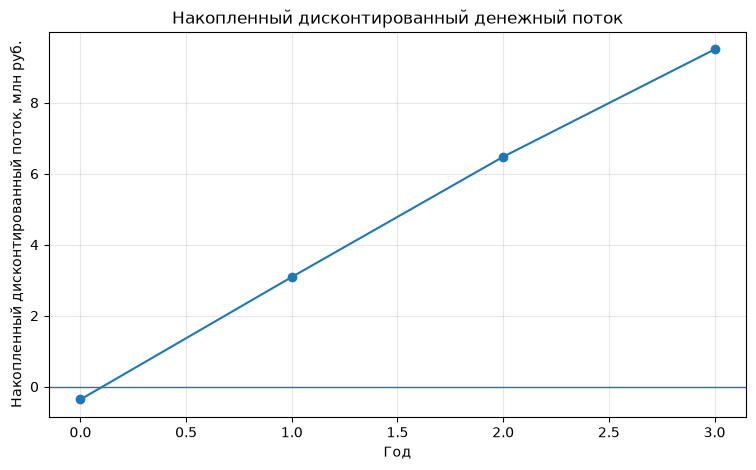

In [ ]:
plt.figure(figsize=(9, 5))
plt.plot(
    cashflow_table["Год"],
    cashflow_table["Накопленный дисконтированный поток, руб."] / 1e6,
    marker="o"
)
plt.axhline(0, linewidth=1)
plt.xlabel("Год")
plt.ylabel("Накопленный дисконтированный поток, млн руб.")
plt.title("Накопленный дисконтированный денежный поток")
plt.grid(alpha=0.3)
plt.show()


## Анализ чувствительности NPV к росту продаж

Проверяется устойчивость проекта к изменению главного неопределённого параметра — дополнительного роста продаж благодаря CRM.


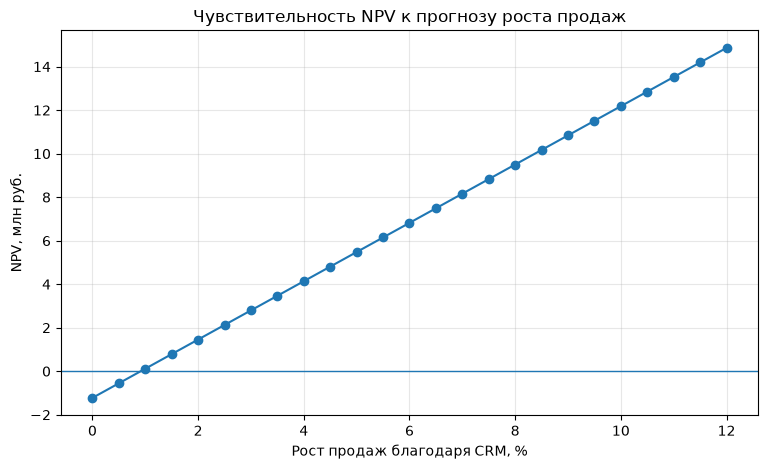

In [ ]:
def npv_for_growth(growth_rate):
    additional_sales_ = annual_sales * growth_rate
    margin_profit_ = additional_sales_ * marginal_profit_rate
    after_tax_ = margin_profit_ * (1 - tax_rate)

    # Реализованная экономия ФОТ, если пользователь её включит
    effect_ = after_tax_ + salary_cash_saving

    cf0 = -(annual_crm_license + implementation_cost)
    cf1 = effect_ * max(0, (12 - adaptation_months) / 12) - annual_crm_license
    cf2 = effect_ - annual_crm_license
    cf3 = effect_ - annual_crm_license

    return (
        cf0
        + cf1 / (1 + discount_rate)
        + cf2 / (1 + discount_rate) ** 2
        + cf3 / (1 + discount_rate) ** 3
    )


growth_values = np.linspace(0, 0.12, 25)
npv_values = np.array([npv_for_growth(g) for g in growth_values])

plt.figure(figsize=(9, 5))
plt.plot(growth_values * 100, npv_values / 1e6, marker="o")
plt.axhline(0, linewidth=1)
plt.xlabel("Рост продаж благодаря CRM, %")
plt.ylabel("NPV, млн руб.")
plt.title("Чувствительность NPV к прогнозу роста продаж")
plt.grid(alpha=0.3)
plt.show()


## Точка безубыточности по росту продаж

In [ ]:
def find_break_even_growth(low=0.0, high=0.20, steps=10001):
    grid = np.linspace(low, high, steps)
    values = np.array([npv_for_growth(g) for g in grid])

    idx = np.where(np.sign(values[:-1]) != np.sign(values[1:]))[0]

    if len(idx) == 0:
        return np.nan

    i = idx[0]
    x1, x2 = grid[i], grid[i + 1]
    y1, y2 = values[i], values[i + 1]

    return x1 + (0 - y1) * (x2 - x1) / (y2 - y1)


break_even_growth = find_break_even_growth()

print(
    f"Точка безубыточности по росту продаж: "
    f"{break_even_growth * 100:.2f}% в год"
)


Точка безубыточности по росту продаж: 0.91% в год


## 8. Итоговая экономическая интерпретация

В базовой модели CRM экономически эффективна, если NPV > 0.

Главный источник эффекта — дополнительная маржинальная прибыль от роста продаж. Высвобождение рабочего времени является механизмом, который позволяет получить этот рост, но не учитывается второй раз как самостоятельная экономия ФОТ.

При изменении исходных параметров необходимо прежде всего проверить:
- NPV;
- ROI;
- срок окупаемости;
- точку безубыточности по росту продаж;
- устойчивость результата на графике чувствительности.



В результате моделирования установлено, что внедрение облачной CRM является экономически эффективным при принятых исходных данных и экономических аксиомах. Основным источником экономического эффекта является увеличение маржинальной прибыли за счет роста продаж на 8%. Годовой прирост продаж составляет 5,76 млн руб., а после учета налога соответствующий прирост прибыли составляет 4,608 млн руб.

CRM также высвобождает 6% рабочего времени менеджеров, что эквивалентно 0,9 FTE и имеет экономическую стоимость 1,296 млн руб. в год. Однако данная величина не была включена в денежный поток дополнительно, поскольку в базовом сценарии численность сотрудников не сокращается, а высвобожденное время используется для увеличения продаж. Такой подход предотвращает двойной учет эффекта.

При стоимости CRM 360 тыс. руб. в год NPV проекта за трехлетний период составляет около 9,50 млн руб., ROI — около 1144%, а срок окупаемости — около 1,94 месяца. Следовательно, проект имеет значительный запас экономической эффективности.

Вместе с тем результат существенно зависит от предположения о росте продаж и предельных затратах на дополнительный объем реализации. Поэтому прогноз роста продаж 8% должен рассматриваться как ключевой параметр модели, требующий проверки на фактических данных после внедрения CRM.

In [ ]:
# ============================================================
# ГЕНЕРАЦИЯ ИТОГОВОГО ОТЧЁТА
# ============================================================

from pathlib import Path
import os
import math

# Проверяем, что основные расчёты уже выполнены
required_vars = [
    "managers",
    "monthly_salary",
    "annual_sales",
    "crm_sales_growth",
    "crm_price_per_user_year",
    "implementation_cost",
    "adaptation_months",
    "freed_time_share",
    "freed_fte",
    "potential_time_value",
    "additional_sales",
    "additional_margin_profit",
    "additional_profit_after_tax",
    "annual_crm_license",
    "total_crm_license",
    "cashflow_table",
    "metrics",
    "break_even_growth",
]

missing = [v for v in required_vars if v not in globals()]

if missing:
    raise RuntimeError(
        "Не выполнены необходимые ячейки модели.\n"
        "Отсутствуют переменные:\n- "
        + "\n- ".join(missing)
        + "\n\nЗапустите notebook сверху вниз, затем повторите эту ячейку."
    )


# ------------------------------------------------------------
# Форматирование
# ------------------------------------------------------------

def money(x):
    return f"{x:,.0f}".replace(",", " ") + " руб."


def pct(x):
    return f"{x * 100:.2f}%"


def value_or_dash(x):
    if x is None:
        return "—"
    if isinstance(x, float) and not math.isfinite(x):
        return "—"
    return f"{x:.2f}"


# ------------------------------------------------------------
# Папка отчётов
# ------------------------------------------------------------

reports_dir = Path("reports")
reports_dir.mkdir(parents=True, exist_ok=True)

report_path = reports_dir / "task_01_report.txt"


# ------------------------------------------------------------
# Формируем таблицу денежных потоков
# ------------------------------------------------------------

cashflow_text = cashflow_table.to_string(index=False)


# ------------------------------------------------------------
# Формируем отчёт
# ------------------------------------------------------------

report_content = f"""
ОТЧЁТ ПО ЭКОНОМИЧЕСКОЙ ЭФФЕКТИВНОСТИ ОБЛАЧНОЙ CRM
============================================================

1. ИСХОДНЫЕ ДАННЫЕ
------------------------------------------------------------

Количество менеджеров:
{managers}

Месячная зарплата одного менеджера:
{money(monthly_salary)}

Текущий годовой оборот:
{money(annual_sales)}

Прогноз роста продаж от CRM:
{pct(crm_sales_growth)}

Стоимость CRM на пользователя в год:
{money(crm_price_per_user_year)}

Стоимость внедрения:
{money(implementation_cost)}

Период адаптации:
{adaptation_months} мес.


2. ЭФФЕКТ ОТ ВЫСВОБОЖДЕНИЯ ВРЕМЕНИ
------------------------------------------------------------

Доля высвобожденного рабочего времени:
{pct(freed_time_share)}

Эквивалент высвобожденного ресурса:
{freed_fte:.2f} FTE

Потенциальная стоимость высвобожденного времени:
{money(potential_time_value)}

Высвобожденное время в базовом сценарии
не учитывается повторно как отдельная экономия ФОТ,
если оно используется для увеличения продаж.


3. ДОПОЛНИТЕЛЬНЫЕ ПРОДАЖИ И ПРИБЫЛЬ
------------------------------------------------------------

Дополнительная выручка:
{money(additional_sales)}

Дополнительная маржинальная прибыль:
{money(additional_margin_profit)}

Дополнительная прибыль после налога:
{money(additional_profit_after_tax)}


4. ЗАТРАТЫ НА CRM
------------------------------------------------------------

Годовая стоимость CRM:
{money(annual_crm_license)}

Стоимость CRM за весь проект:
{money(total_crm_license)}

Разовые затраты на внедрение:
{money(implementation_cost)}


5. ДЕНЕЖНЫЕ ПОТОКИ ПРОЕКТА
------------------------------------------------------------

{cashflow_text}


6. ИТОГОВЫЕ ПОКАЗАТЕЛИ
------------------------------------------------------------

NPV:
{money(metrics["NPV, руб."])}

Совокупный эффект:
{money(metrics["Совокупный эффект, руб."])}

Совокупные затраты:
{money(metrics["Совокупные затраты, руб."])}

Совокупный чистый эффект:
{money(metrics["Совокупный чистый эффект, руб."])}

ROI:
{metrics["ROI, %"]:.2f}%

Простой срок окупаемости:
{value_or_dash(metrics["Простой срок окупаемости, мес."])} мес.

Дисконтированный срок окупаемости:
{value_or_dash(metrics["Дисконтированный срок окупаемости, мес."])} мес.

Точка безубыточности по росту продаж:
{break_even_growth * 100:.2f}% в год


7. КРАТКИЙ ВЫВОД
------------------------------------------------------------

При текущих исходных данных проект оценивается по показателям
NPV, ROI, сроку окупаемости и точке безубыточности по росту продаж.

Основной экономический эффект формируется за счёт дополнительной
маржинальной прибыли от роста продаж.

Высвобождение рабочего времени менеджеров рассматривается как
механизм, позволяющий обеспечить дополнительный рост продаж,
и не должно учитываться повторно как самостоятельная экономия,
если численность сотрудников не сокращается.

Ключевой параметр модели — фактический рост продаж после
внедрения CRM.

Точка безубыточности по росту продаж:
{break_even_growth * 100:.2f}% в год.


============================================================
ОТЧЁТ СФОРМИРОВАН АВТОМАТИЧЕСКИ
============================================================
"""


# ------------------------------------------------------------
# Сохраняем
# ------------------------------------------------------------

with open(report_path, "w", encoding="utf-8") as f:
    f.write(report_content)


# ------------------------------------------------------------
# Быстрый вывод прямо в notebook
# ------------------------------------------------------------

print("=" * 60)
print("ОТЧЁТ СФОРМИРОВАН")
print("=" * 60)

print(f"Файл: {report_path}")
print(f"Размер: {os.path.getsize(report_path):,} байт")

print()
print("КЛЮЧЕВЫЕ РЕЗУЛЬТАТЫ")
print("-" * 60)

print(f"NPV:                  {money(metrics['NPV, руб.'])}")
print(f"ROI:                  {metrics['ROI, %']:.2f}%")
print(
    f"Окупаемость:          "
    f"{value_or_dash(metrics['Простой срок окупаемости, мес.'])} мес."
)
print(
    f"Discounted payback:   "
    f"{value_or_dash(metrics['Дисконтированный срок окупаемости, мес.'])} мес."
)
print(f"Break-even growth:    {break_even_growth * 100:.2f}%")

print("=" * 60)

ОТЧЁТ СФОРМИРОВАН
Файл: reports\task_01_report.txt
Размер: 5,329 байт

КЛЮЧЕВЫЕ РЕЗУЛЬТАТЫ
------------------------------------------------------------
NPV:                  9 500 122 руб.
ROI:                  833.33%
Окупаемость:          1.94 мес.
Discounted payback:   1.96 мес.
Break-even growth:    0.91%
